In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import explained_variance_score, mean_absolute_error, mean_squared_error, r2_score

def regression_results(y_true, y_pred, regr_type):

    # Regression metrics
    ev = explained_variance_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred) 
    mse = mean_squared_error(y_true, y_pred) 
    r2 = r2_score(y_true, y_pred)
    
    print('Evaluation metrics for ' + regr_type + ' Linear Regression')
    print('explained_variance: ',  round(ev,4)) 
    print('r2: ', round(r2,4))
    print('MAE: ', round(mae,4))
    print('MSE: ', round(mse,4))
    print('RMSE: ', round(np.sqrt(mse),4))
    print()


In [6]:
# Generate synthetic data
noise=1
np.random.seed(42)
X = 2 * np.random.rand(1000, 1)
y = 4 + 3 * X + noise*np.random.randn(1000, 1)  # Linear relationship with some noise
y_ideal =  4 + 3 * X
# Specify the portion of the dataset to add outliers (e.g., the last 20%)
y_outlier = pd.Series(y.reshape(-1).copy())

# Identify indices where the feature variable X is greater than a certain threshold
threshold = 1.5  # Example threshold to add outliers for larger feature values
outlier_indices = np.where(X.flatten() > threshold)[0]

# Add outliers at random locations within the specified portion
num_outliers = 5  # Number of outliers to add
selected_indices = np.random.choice(outlier_indices, num_outliers, replace=False)

# Modify the target values at these indices to create outliers (add significant noise)
y_outlier[selected_indices] += np.random.uniform(50, 100, num_outliers)
y_outlier[selected_indices]

446     85.332136
241     93.019238
55      71.517321
308    100.046501
716     88.286603
dtype: float64

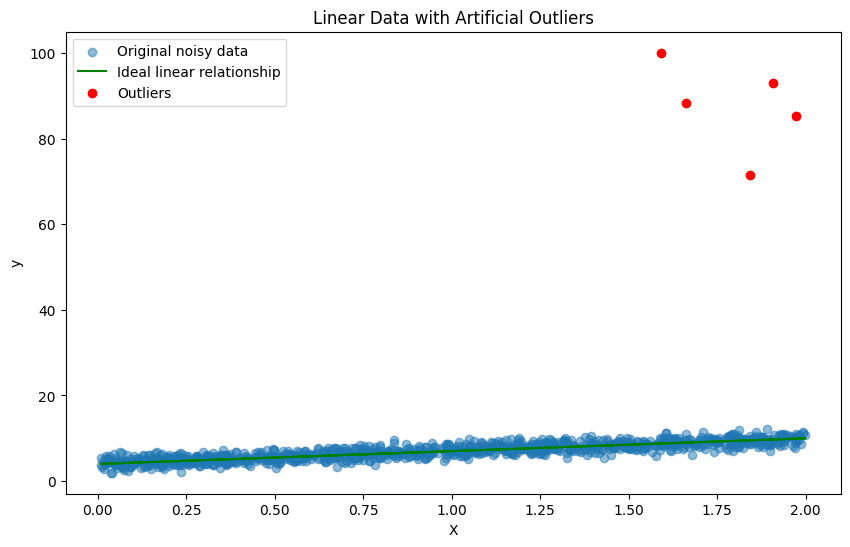

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(X, y, label="Original noisy data", alpha=0.5)
plt.plot(X.flatten(), y_ideal.flatten(),
         color="green", label="Ideal linear relationship")

plt.scatter(X[selected_indices], y_outlier.iloc[selected_indices],
            color="red", label="Outliers", zorder=3)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Data with Artificial Outliers")
plt.legend()
plt.show()


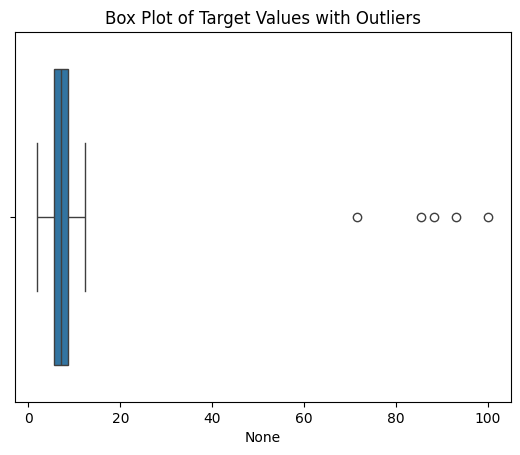

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=y_outlier)
plt.title("Box Plot of Target Values with Outliers")
plt.show()

In [21]:
from sklearn.linear_model import Lasso

lin_reg = LinearRegression()
lin_reg.fit(X, y_outlier)
y_outlier_pred_lin = lin_reg.predict(X)
y_outlier_pred_lin


array([ 6.54058425, 10.97017302,  9.28866543,  8.26359131,  4.86060569,
        4.86042025,  4.10768772, 10.32024927,  8.28247693,  9.10475957,
        3.819397  , 11.11774709, 10.06090833,  5.29359371,  5.05900301,
        5.07114643,  6.00013887,  7.69543726,  6.9819093 ,  5.900095  ,
        8.36502906,  4.73356428,  5.90713337,  6.47771022,  7.16738043,
        9.69752525,  5.19622351,  7.61454487,  8.21558851,  4.01825245,
        8.33190912,  4.97212288,  4.16125709, 10.95611356, 11.0848595 ,
        9.87604972,  6.00299514,  4.41204148,  8.92148269,  7.04500782,
        4.59936659,  7.46803187,  3.92552144, 10.65193944,  5.65062803,
        8.75457195,  6.05755876,  7.65939307,  7.86421698,  5.08229351,
       11.11524679,  9.62031427, 10.88395004, 10.54051782,  8.25775997,
       10.74845247,  4.34146924,  5.16784796,  4.00884916,  6.16226268,
        6.64926988,  5.74725805, 10.03242353,  6.40384058,  5.82095057,
        7.8333561 ,  4.74456083,  9.82838171,  4.23428516, 11.24

In [17]:
ridge_reg = Ridge(alpha = 1)
ridge_reg.fit(X, y_outlier)
y_outlier_pred_ridge = ridge_reg.predict(X)
y_outlier_pred_ridge

array([ 6.54318521, 10.95982331,  9.2832319 ,  8.26115476,  4.86811835,
        4.86793346,  4.11740167, 10.31179973,  8.27998517,  9.09986372,
        3.82995382, 11.10696593, 10.05321701,  5.29984046,  5.06593563,
        5.07804354,  6.00431991,  7.6946618 ,  6.98321997,  5.90456854,
        8.36229594,  4.74144838,  5.91158633,  6.480495  ,  7.16814884,
        9.69089635,  5.20275494,  7.61400592,  8.2132923 ,  4.02822788,
        8.32927283,  4.9793095 ,  4.17081442, 10.94580496, 11.07417449,
        9.86889887,  6.00716783,  4.4208656 ,  8.91712268,  7.04613401,
        4.60764304,  7.46792127,  3.93576798, 10.64252014,  5.65583093,
        8.75069994,  6.06157193,  7.658723  ,  7.86294807,  5.08915804,
       11.10447293,  9.61391111, 10.87385242, 10.53142428,  8.25534047,
       10.738751  ,  4.35049969,  5.17446235,  4.01885208,  6.16596973,
        6.65155308,  5.75217844, 10.02481549,  6.40684133,  5.8256555 ,
        7.83217742,  4.75241277,  9.82137023,  4.24362898, 11.23

In [19]:
lasso_reg = Lasso(alpha = 2)
lasso_reg.fit(X, y_outlier)
y_outlier_pred_lasso = lasso_reg.predict(X)
y_outlier_pred_lasso


array([7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020449,
       7.43020449, 7.43020449, 7.43020449, 7.43020449, 7.43020

In [22]:
regression_results(y, y_outlier_pred_lin, 'Ordinary')
regression_results(y, y_outlier_pred_ridge, 'Ridge')
regression_results(y, y_outlier_pred_lasso, 'Lasso')

Evaluation metrics for Ordinary Linear Regression
explained_variance:  0.6748
r2:  0.6357
MAE:  0.9468
MSE:  1.4164
RMSE:  1.1901

Evaluation metrics for Ridge Linear Regression
explained_variance:  0.6766
r2:  0.6375
MAE:  0.9443
MSE:  1.4094
RMSE:  1.1872

Evaluation metrics for Lasso Linear Regression
explained_variance:  0.0
r2:  -0.0391
MAE:  1.6802
MSE:  4.0399
RMSE:  2.0099



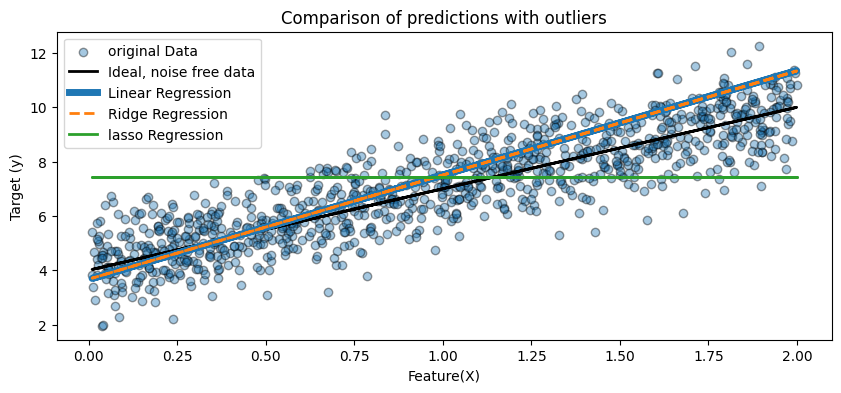

In [27]:
plt.figure(figsize = (10, 4))
plt.scatter(X, y, alpha = 0.4, ec = 'k', label = 'original Data')
plt.plot(X, y_ideal, lw = 2, color = 'k', label = 'Ideal, noise free data')
plt.plot(X, y_outlier_pred_lin, lw = 5, label = 'Linear Regression')
plt.plot(X, y_outlier_pred_ridge, linestyle = '--', lw = 2, label = 'Ridge Regression')
plt.plot(X, y_outlier_pred_lasso, lw = 2, label = 'lasso Regression')

plt.xlabel('Feature(X)')
plt.ylabel('Target (y)')
plt.title('Comparison of predictions with outliers')
plt.legend(loc = 'best')
plt.show()

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.5, random_state = 42)

lasso = Lasso(alpha=0.1)
ridge = Ridge(alpha=1.0)
linear = LinearRegression()

# Fit the models
lasso.fit(X_train, y_train)
ridge.fit(X_train, y_train)
linear.fit(X_train, y_train)



LinearRegression()

In [33]:
regression_results(y_test, y_pred_linear, 'Ordinary')
regression_results(y_test, y_pred_ridge, 'Ridge')
regression_results(y_test, y_pred_lasso, 'Lasso')

Evaluation metrics for Ordinary Linear Regression
explained_variance:  0.7638
r2:  0.7633
MAE:  0.7679
MSE:  0.9441
RMSE:  0.9717

Evaluation metrics for Ridge Linear Regression
explained_variance:  0.7635
r2:  0.763
MAE:  0.769
MSE:  0.9455
RMSE:  0.9724

Evaluation metrics for Lasso Linear Regression
explained_variance:  0.7507
r2:  0.7503
MAE:  0.7956
MSE:  0.9959
RMSE:  0.9979



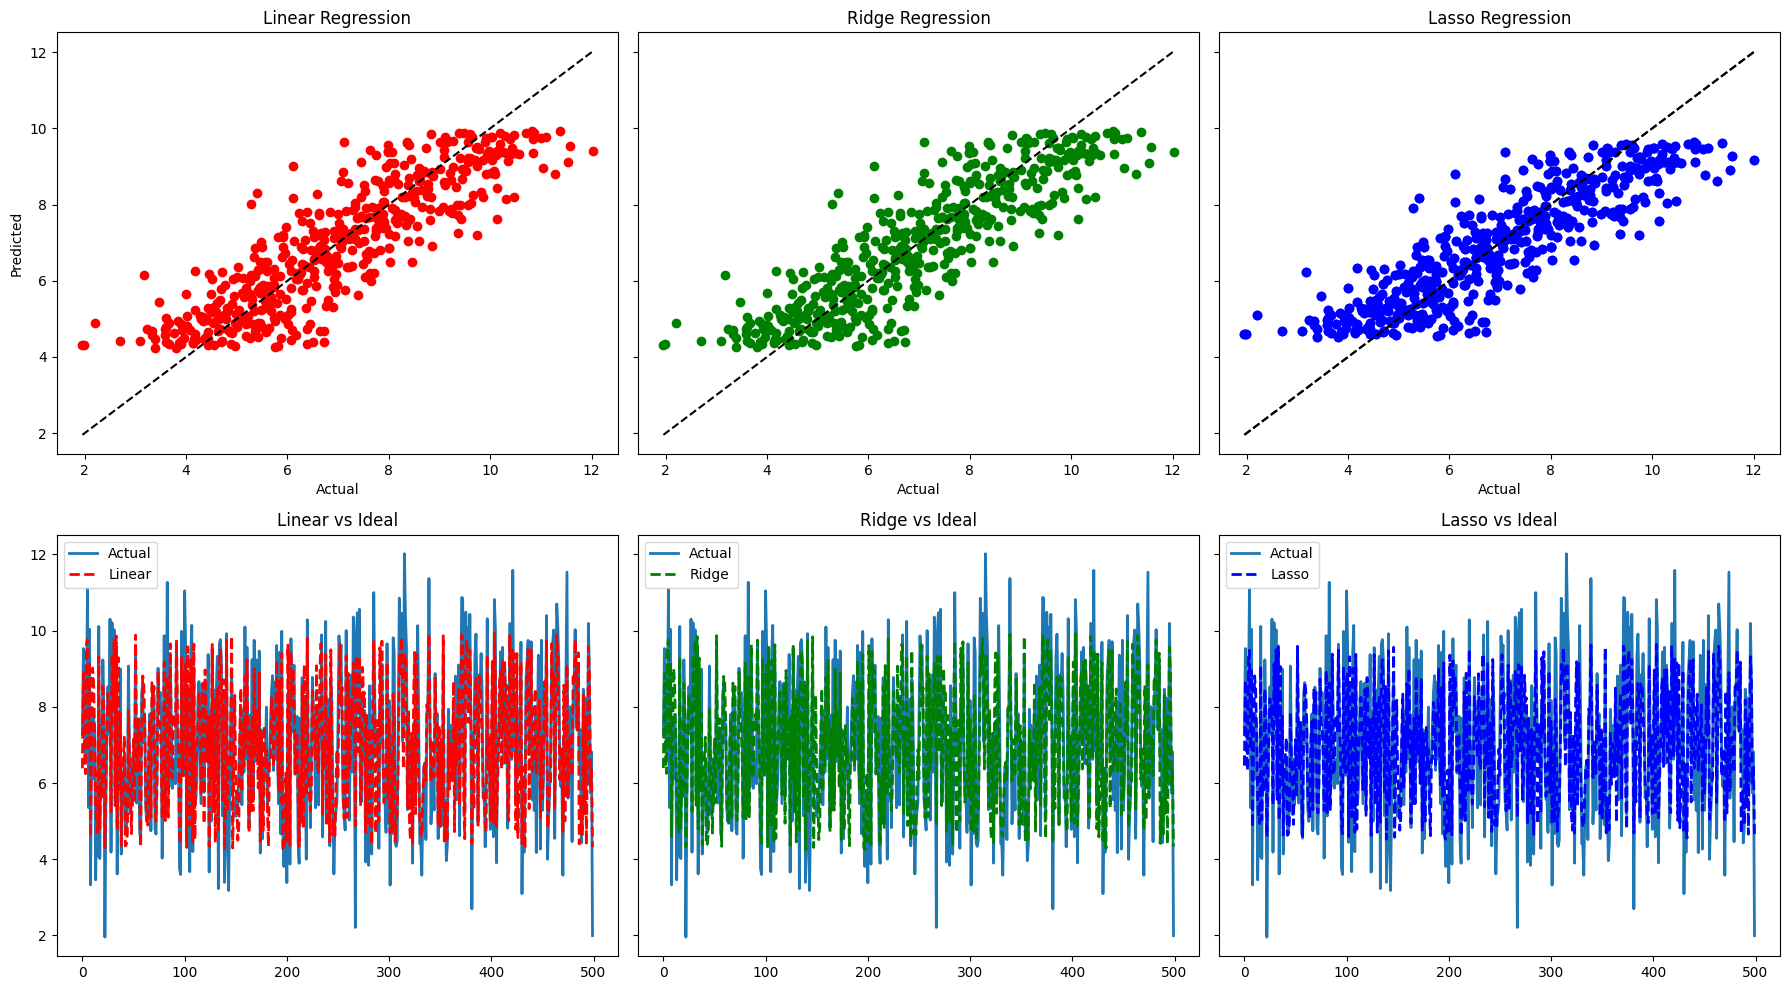

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True)

axes[0,0].scatter(y_test, y_pred_linear, color="red", label="Linear")
axes[0,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,0].set_title("Linear Regression")
axes[0,0].set_xlabel("Actual",)
axes[0,0].set_ylabel("Predicted",)

axes[0,2].scatter(y_test, y_pred_lasso, color="blue", label="Lasso")
axes[0,2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,2].set_title("Lasso Regression",)
axes[0,2].set_xlabel("Actual",)

axes[0,1].scatter(y_test, y_pred_ridge, color="green", label="Ridge")
axes[0,1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,1].set_title("Ridge Regression",)
axes[0,1].set_xlabel("Actual",)

axes[0,2].scatter(y_test, y_pred_lasso, color="blue", label="Lasso")
axes[0,2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,2].set_title("Lasso Regression",)
axes[0,2].set_xlabel("Actual",)


# Line plots for predictions compared to actual and ideal predictions
axes[1,0].plot(y_test, label="Actual", lw=2)
axes[1,0].plot(y_pred_linear, '--', lw=2, color='red', label="Linear")
axes[1,0].set_title("Linear vs Ideal",)
axes[1,0].legend()
 
axes[1,1].plot(y_test, label="Actual", lw=2)
# axes[1,1].plot(ideal_test, '--', label="Ideal", lw=2, color="purple")
axes[1,1].plot(y_pred_ridge, '--', lw=2, color='green', label="Ridge")
axes[1,1].set_title("Ridge vs Ideal",)
axes[1,1].legend()
 
axes[1,2].plot(y_test, label="Actual", lw=2)
axes[1,2].plot(y_pred_lasso, '--', lw=2, color='blue', label="Lasso")
axes[1,2].set_title("Lasso vs Ideal",)
axes[1,2].legend()
 
plt.tight_layout()
plt.show()